# Confirming Environmental Parameter Relationships

This notebook validates the robustness of the relationships identified in the spatial correlation mapping (Scripts 35 & 36).
While spatial maps show *where* correlations exist, this notebook confirms whether the relationship between the **regional environmental driver** and the **regional DO pattern (PC Score)** is physically robust over time.

### Process:
1. **Identify Relevant Area**: Filter for stations within a specific water mass (e.g., Osaka Bay) that showed significant correlation.
2. **Calculate Regional Average**: Average the environmental parameter across these significant stations to create a single regional time series, reducing local noise.
3. **Scatter Plot Validation**: Plot the regional environmental average against the PC score. A robust relationship will show a clear trend across years rather than being driven by a few outliers.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import linregress
import sys
from pathlib import Path

# Add project root to sys.path
project_root = Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from scripts.paths import ProjectPaths

# Apply global style
plt.style.use(str(ProjectPaths.PROJECT_ROOT / 'project_style.mplstyle'))


## 1. Configuration
Define the Principal Component, the environmental parameter, and the target region you want to investigate. You can adjust these based on the "hotspots" you identified in the correlation maps.


In [11]:
TARGET_PC = "PC1"
TARGET_PARAM = "Spring_1_CHLA"
TARGET_REGION = "Suo Nada"
P_VALUE_THRESHOLD = 0.05


## 2. Load Data
We need the PC scores, the station-wise correlation results, and the full merged dataset to extract the raw time series.


In [12]:
print("Loading data...")
# Load merged data for raw time series
merged_df = pd.read_feather(ProjectPaths.MERGED_DATA_FILE)
merged_df['zettaicode'] = merged_df['zettaicode'].astype(str).str.zfill(8)

# Load PC scores
subset_dir = ProjectPaths.get_subset_dir('Summer', 'bottom')
pca_scores = pd.read_csv(subset_dir / 'pca_scores.csv', index_col=0)
pca_scores.index = pca_scores.index.astype(int)

# Load correlation results to find significant stations
corr_path = subset_dir / f'pca_env_corr_{TARGET_PC.lower()}.csv'
if not corr_path.exists():
    corr_path = subset_dir / f'pca_nutr_corr_{TARGET_PC.lower()}.csv'
    
corr_df = pd.read_csv(corr_path, index_col=0)
corr_df.index = corr_df.index.astype(str).str.zfill(8)

# Map stations to their divisions
station_regions = merged_df[['zettaicode', 'division']].drop_duplicates().set_index('zettaicode')['division']


Loading data...


## 3. Extract and Average Regional Data
We filter the stations to only include those in our `TARGET_REGION` that have a statistically significant relationship with our `TARGET_PC`. Then, we average their time series to create the regional signal.


In [13]:
# 1. Find significant stations in the target region
p_col = TARGET_PARAM + '_pval'
sig_stations = corr_df[(corr_df[p_col] <= P_VALUE_THRESHOLD)].index
region_stations = station_regions[station_regions == TARGET_REGION].index

valid_stations = list(set(sig_stations).intersection(set(region_stations)))
print(f"Found {len(valid_stations)} significant stations for {TARGET_PARAM} in {TARGET_REGION}.")

if len(valid_stations) == 0:
    raise ValueError("No stations match the criteria. Try a different region or parameter.")

# 2. Extract time series for these stations
# Basic mapping from standard parameter names to raw column names
param_base = TARGET_PARAM.split('_')[-1].lower()
param_mapping = {
    'chla': 'chlorophyl',
    'wtemp': 'wtemp',
    'salt2': 'salt2',
    'density': 'density',
    'cod2': 'cod2',
    'din2': 'din2',
    'dip2': 'dip2',
    'tn2': 'tn2',
    'tp2': 'tp2'
}
raw_param = param_mapping.get(param_base, param_base)

# Parse season from parameter name, or default to Summer
season = "Summer"
if "Spring" in TARGET_PARAM: season = "Spring"
elif "Winter" in TARGET_PARAM: season = "Winter"
elif "Autumn" in TARGET_PARAM: season = "Autumn"

mask = (merged_df['season'] == season) & (merged_df['zettaicode'].isin(valid_stations))

# Parse layer from parameter name if present
if "_1_" in TARGET_PARAM:
    mask &= (merged_df['saisuipoin'] == 1)
elif "_2_" in TARGET_PARAM:
    mask &= (merged_df['saisuipoin'] == 2)

subset = merged_df.loc[mask, ['surveyyear', 'zettaicode', raw_param]].copy()
subset[raw_param] = pd.to_numeric(subset[raw_param], errors='coerce')

# 3. Calculate Regional Average per year
regional_avg = subset.groupby('surveyyear')[raw_param].mean()
regional_avg.index = regional_avg.index.astype(int)

# Combine with PC scores
analysis_df = pd.DataFrame({
    'PC_Score': pca_scores[TARGET_PC],
    'Regional_Param_Avg': regional_avg
}).dropna()

display(analysis_df.head())


Found 5 significant stations for Spring_1_CHLA in Suo Nada.


,PC_Score,Regional_Param_Avg
1982,-1.209830,1.960000
1984,-3.053928,3.780000
1985,-8.373698,5.583333
1986,-3.945572,7.480000
1987,-1.482823,3.940000


## 4. Visualization & Regression
Plot the relationship to visually confirm its robustness. A robust relationship will show points tightly clustered around the regression line, rather than being skewed by one or two extreme years.


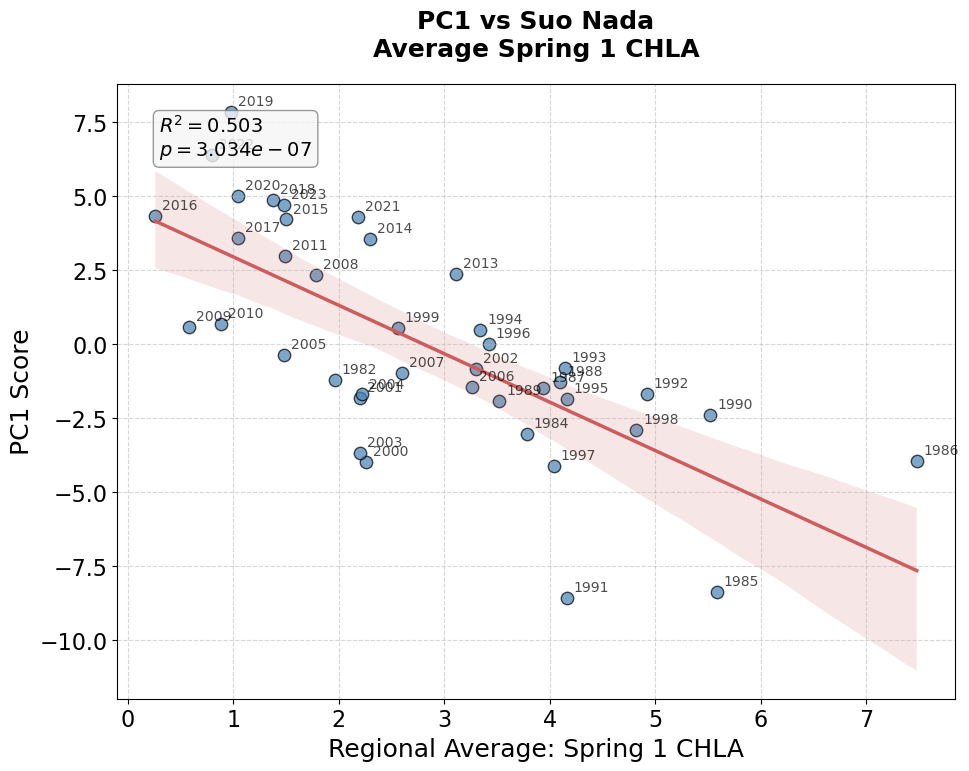

In [14]:
fig, ax = plt.subplots(figsize=(10, 8))

# Calculate regression
slope, intercept, r_value, p_value, std_err = linregress(analysis_df['Regional_Param_Avg'], analysis_df['PC_Score'])
r_squared = r_value**2

# Plot using Seaborn for automatic regression line and confidence interval
sns.regplot(
    data=analysis_df, 
    x='Regional_Param_Avg', 
    y='PC_Score',
    ax=ax,
    scatter_kws={'s': 80, 'alpha': 0.7, 'edgecolor': 'k', 'color': 'steelblue'},
    line_kws={'color': 'indianred', 'linewidth': 2.5}
)

# Annotate points with the year (useful for finding outliers)
for year, row in analysis_df.iterrows():
    ax.annotate(str(year), (row['Regional_Param_Avg'], row['PC_Score']), 
                xytext=(5, 5), textcoords='offset points', fontsize=10, alpha=0.7)

# Formatting
ax.set_title(f"{TARGET_PC} vs {TARGET_REGION}\nAverage {TARGET_PARAM.replace('_', ' ')}", pad=20)
ax.set_xlabel(f"Regional Average: {TARGET_PARAM.replace('_', ' ')}")
ax.set_ylabel(f"{TARGET_PC} Score")
ax.grid(True, linestyle='--', alpha=0.5)

# Add statistics text box
stats_text = f"$R^2 = {r_squared:.3f}$\n$p = {p_value:.3e}$"
props = dict(boxstyle='round', facecolor='whitesmoke', alpha=0.8, edgecolor='gray')
ax.text(0.05, 0.95, stats_text, transform=ax.transAxes, fontsize=14,
        verticalalignment='top', bbox=props)

plt.tight_layout()
plt.show()
